TensorFlow Version: 2.21.0
11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Training Data Shape: (60000, 28, 28)
Testing Data Shape: (10000, 28, 28)
Data Type: uint8
Pixel Value Range: 0 - 255


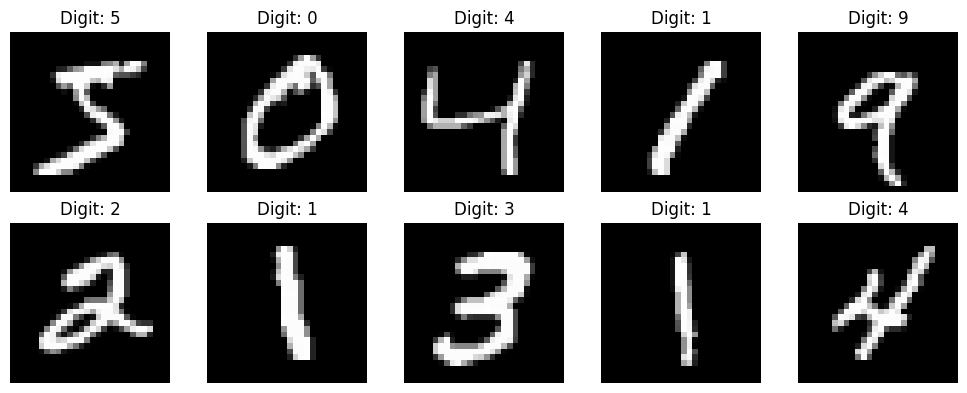

Normalized Training Shape: (60000, 784)
Normalized Testing Shape: (10000, 784)
Training and testing datasets prepared successfully!


In [1]:
# GANIKA R - 24BAD025
# TASK A: DATASET PREPARATION

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
import numpy as np
import matplotlib.pyplot as plt

print("TensorFlow Version:", tf.__version__)

# Load MNIST dataset
(x_train, y_train), (x_test, y_test) = keras.datasets.mnist.load_data()

# Explore dataset
print("Training Data Shape:", x_train.shape)
print("Testing Data Shape:", x_test.shape)
print("Data Type:", x_train.dtype)
print("Pixel Value Range:", x_train.min(), "-", x_train.max())

# Display sample images
plt.figure(figsize=(10, 4))

for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_train[i], cmap='gray')
    plt.title(f"Digit: {y_train[i]}")
    plt.axis('off')

plt.tight_layout()
plt.show()

# Normalize pixel values between 0 and 1
x_train = x_train.astype('float32') / 255.0
x_test = x_test.astype('float32') / 255.0

# Reshape images into one-dimensional vectors
x_train = x_train.reshape(-1, 784)
x_test = x_test.reshape(-1, 784)

# Use input data as target output
print("Normalized Training Shape:", x_train.shape)
print("Normalized Testing Shape:", x_test.shape)

print("Training and testing datasets prepared successfully!")

In [2]:
# TASK B: IMPLEMENTING THE AUTOENCODER

# Define input dimension
input_dim = 784
encoding_dim = 32

# Build Encoder
input_layer = keras.Input(shape=(input_dim,))

encoder_layer = layers.Dense(128, activation='relu')(input_layer)

bottleneck = layers.Dense(encoding_dim, activation='relu')(encoder_layer)

encoder = keras.Model(input_layer, bottleneck, name="Encoder")

# Build Decoder
decoder_input = keras.Input(shape=(encoding_dim,))

decoder_layer = layers.Dense(128, activation='relu')(decoder_input)

decoder_output = layers.Dense(784, activation='sigmoid')(decoder_layer)

decoder = keras.Model(decoder_input, decoder_output, name="Decoder")

# Combine Encoder and Decoder
autoencoder_input = keras.Input(shape=(input_dim,))

encoded = encoder(autoencoder_input)
decoded = decoder(encoded)

autoencoder = keras.Model(autoencoder_input, decoded, name="Autoencoder")

# Compile model
autoencoder.compile(
    optimizer='adam',
    loss='mse'
)

# Display model summaries
print("ENCODER SUMMARY")
encoder.summary()

print("DECODER SUMMARY")
decoder.summary()

print("COMPLETE AUTOENCODER SUMMARY")
autoencoder.summary()

print("Autoencoder model created successfully!")

ENCODER SUMMARY


Model: "Encoder"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         4,128 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 104,608 (408.62 KB)

 Trainable params: 104,608 (408.62 KB)

 Non-trainable params: 0 (0.00 B)

... (9 outputs left out)

 Total params: 209,968 (820.19 KB)

 Trainable params: 209,968 (820.19 KB)

 Non-trainable params: 0 (0.00 B)

Autoencoder model created successfully!


Epoch 1/20
235/235 ━━━━━━━━━━━━━━━━━━━━ 5s 13ms/step - loss: 0.0583 - val_loss: 0.0322
Epoch 2/20
235/235 ━━━━━━━━━━━━━━━━━━━━ 3s 11ms/step - loss: 0.0260 - val_loss: 0.0212
Epoch 3/20
235/235 ━━━━━━━━━━━━━━━━━━━━ 3s 11ms/step - loss: 0.0196 - val_loss: 0.0174
Epoch 4/20
235/235 ━━━━━━━━━━━━━━━━━━━━ 5s 12ms/step - loss: 0.0165 - val_loss: 0.0149
Epoch 5/20
235/235 ━━━━━━━━━━━━━━━━━━━━ 3s 12ms/step - loss: 0.0145 - val_loss: 0.0134
Epoch 6/20
235/235 ━━━━━━━━━━━━━━━━━━━━ 3s 11ms/step - loss: 0.0131 - val_loss: 0.0122
Epoch 7/20
235/235 ━━━━━━━━━━━━━━━━━━━━ 4s 15ms/step - loss: 0.0121 - val_loss: 0.0113
Epoch 8/20
235/235 ━━━━━━━━━━━━━━━━━━━━ 4s 15ms/step - loss: 0.0113 - val_loss: 0.0106
Epoch 9/20
235/235 ━━━━━━━━━━━━━━━━━━━━ 3s 11ms/step - loss: 0.0108 - val_loss: 0.0103
Epoch 10/20
235/235 ━━━━━━━━━━━━━━━━━━━━ 3s 12ms/step - loss: 0.0105 - val_loss: 0.0103
Epoch 11/20
235/235 ━━━━━━━━━━━━━━━━━━━━ 3s 12ms/step - loss: 0.0102 - val_loss: 0.0097
Epoch 12/20
235/235 ━━━━━━━━━━━━━━━━━━━━ 

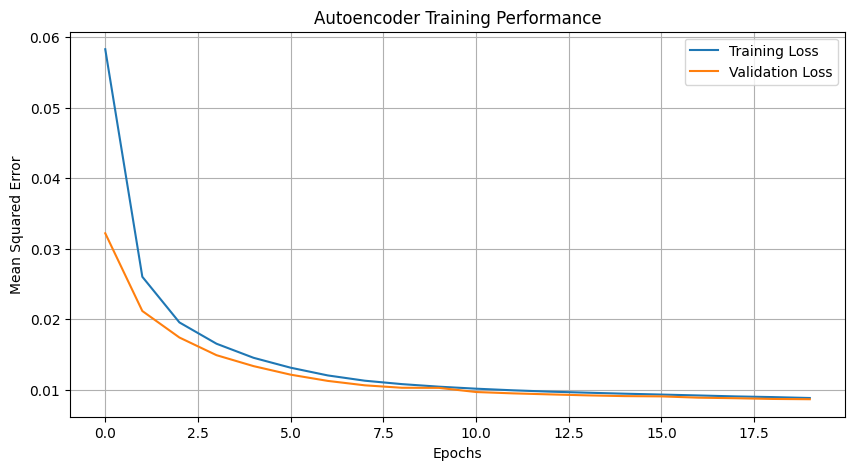

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 70ms/step


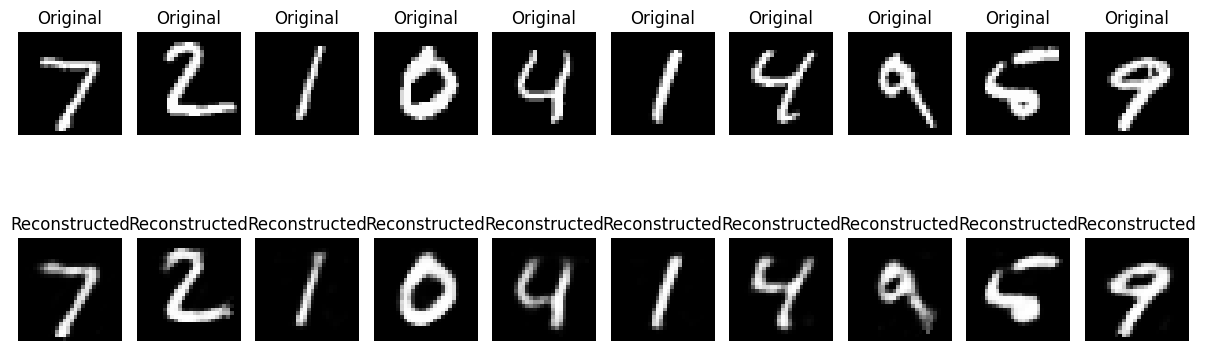

Model training and evaluation completed successfully!


In [3]:
# TASK C: MODEL TRAINING AND PERFORMANCE EVALUATION

# Train the Autoencoder
history = autoencoder.fit(
    x_train,
    x_train,
    epochs=20,
    batch_size=256,
    shuffle=True,
    validation_data=(x_test, x_test)
)

# Evaluate model
test_loss = autoencoder.evaluate(x_test, x_test, verbose=0)

print("Test Reconstruction MSE:", test_loss)

# Plot training and validation loss
plt.figure(figsize=(10, 5))

plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')

plt.xlabel('Epochs')
plt.ylabel('Mean Squared Error')
plt.title('Autoencoder Training Performance')
plt.legend()
plt.grid()

plt.show()

# Reconstruct test images
reconstructed_images = autoencoder.predict(x_test[:10])

# Display original and reconstructed images
plt.figure(figsize=(12, 5))

for i in range(10):

    # Original image
    plt.subplot(2, 10, i + 1)
    plt.imshow(x_test[i].reshape(28, 28), cmap='gray')
    plt.title("Original")
    plt.axis('off')

    # Reconstructed image
    plt.subplot(2, 10, i + 11)
    plt.imshow(reconstructed_images[i].reshape(28, 28), cmap='gray')
    plt.title("Reconstructed")
    plt.axis('off')

plt.tight_layout()
plt.show()

print("Model training and evaluation completed successfully!")

313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
Original Data Dimension: (10000, 784)
Compressed Data Dimension: (10000, 32)


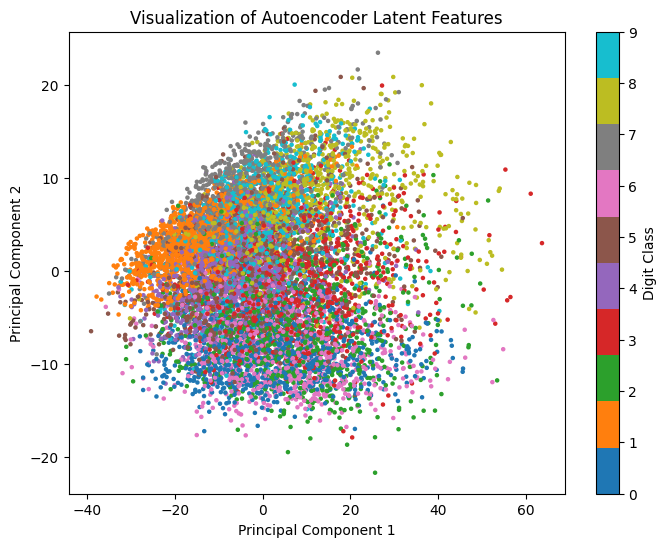

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 60ms/step


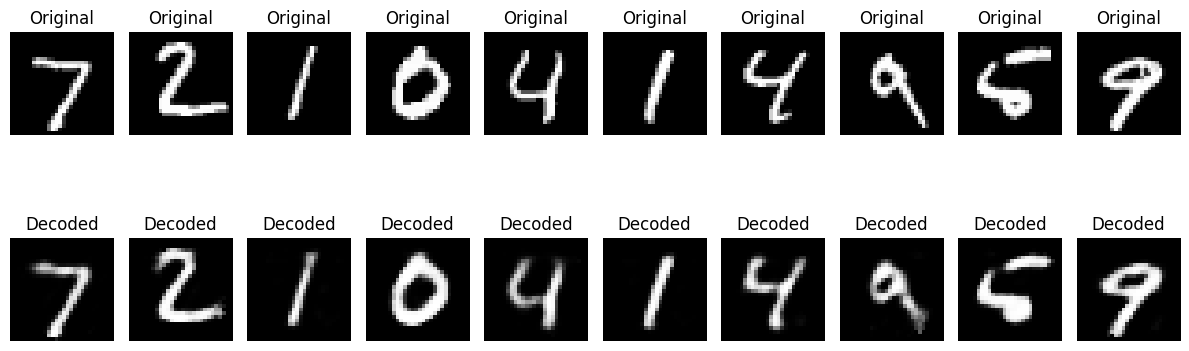

Encoder, Decoder and Autoencoder saved successfully!

EXPERIMENT COMPLETED SUCCESSFULLY
Original Dimension: 784
Compressed Dimension: 32
Dimensionality Reduction: 784 to 32
Feature Visualization: Completed
Image Reconstruction: Completed


In [4]:
# TASK D: DIMENSIONALITY REDUCTION AND FEATURE VISUALIZATION

# Extract latent-space representations
latent_features = encoder.predict(x_test)

print("Original Data Dimension:", x_test.shape)
print("Compressed Data Dimension:", latent_features.shape)

# Visualize latent representations using PCA
from sklearn.decomposition import PCA

pca = PCA(n_components=2)

reduced_features = pca.fit_transform(latent_features)

plt.figure(figsize=(8, 6))

scatter = plt.scatter(
    reduced_features[:, 0],
    reduced_features[:, 1],
    c=y_test,
    cmap='tab10',
    s=5
)

plt.colorbar(scatter, label='Digit Class')
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.title('Visualization of Autoencoder Latent Features')

plt.show()

# Reconstruct selected test samples using Decoder
selected_features = encoder.predict(x_test[:10])
decoded_images = decoder.predict(selected_features)

# Compare original and reconstructed images
plt.figure(figsize=(12, 5))

for i in range(10):

    plt.subplot(2, 10, i + 1)
    plt.imshow(x_test[i].reshape(28, 28), cmap='gray')
    plt.title("Original")
    plt.axis('off')

    plt.subplot(2, 10, i + 11)
    plt.imshow(decoded_images[i].reshape(28, 28), cmap='gray')
    plt.title("Decoded")
    plt.axis('off')

plt.tight_layout()
plt.show()

# Save trained models
encoder.save("Encoder.keras")
decoder.save("Decoder.keras")
autoencoder.save("Autoencoder.keras")

print("Encoder, Decoder and Autoencoder saved successfully!")

print("\nEXPERIMENT COMPLETED SUCCESSFULLY")
print("Original Dimension: 784")
print("Compressed Dimension: 32")
print("Dimensionality Reduction: 784 to 32")
print("Feature Visualization: Completed")
print("Image Reconstruction: Completed")